# Heatwave TMAX forecasting: rebuilt model experiment

## tl;dr

This notebook reviews the completed leakage-controlled rerun. `Dynamic_ARIMA` was selected using 2022–2023 validation RMSE (2.242°C), while `Ridge_AR` was numerically best on the untouched January–June 2024 test (RMSE 2.679°C versus 2.742°C). Their paired station-week MAE difference was not statistically supported at 95%. Heatwave event detection was harder: persistence had the highest final event F1 (0.514), so continuous-temperature accuracy and event detection must be reported separately.

The notebook reads the saved, fully reproducible outputs. The complete training implementation is in `src/heatwave_model_redo.py`.

## Context & methods

The source data contain station-level daily `TMAX`, `TMIN`, and `TAVG`. This rebuild targets only `TMAX` and uses expanding outer folds with seven-day rolling origins: validation years 2022 and 2023, followed by a final 2024H1 holdout.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
OUTPUTS = ROOT / "outputs"
METRICS = OUTPUTS / "metrics"
FIGURES = OUTPUTS / "figures"
AUDIT = OUTPUTS / "audit"

with (OUTPUTS / "run_summary.json").open() as handle:
    summary = json.load(handle)
with (AUDIT / "data_quality_audit.json").open() as handle:
    data_audit = json.load(handle)
with (AUDIT / "experiment_config.json").open() as handle:
    experiment = json.load(handle)

validation = pd.read_csv(METRICS / "validation_model_summary.csv")
regression = pd.read_csv(METRICS / "regression_metrics_by_fold.csv")
uncertainty = pd.read_csv(METRICS / "final_test_uncertainty.csv")
paired = pd.read_csv(METRICS / "final_test_paired_block_comparisons.csv")
heatwave = pd.read_csv(METRICS / "heatwave_day_and_event_metrics.csv")
station_profile = pd.read_csv(AUDIT / "station_data_profile.csv")

print(f"Validation-selected model: {summary['selected_model_from_validation']}")
print(f"Data range: {data_audit['start_date']} to {data_audit['end_date']}")

Validation-selected model: Dynamic_ARIMA
Data range: 2019-01-01 to 2024-06-30


### Key assumptions

- Forecasts are recursive inside each seven-day block; the next block may use newly observed history.
- Hyperparameters are chosen within each outer training period, never from its evaluation dates.
- The final 2024H1 data are not used for model selection.
- The primary station-level heatwave definition is `TMAX > 36°C` for at least three consecutive days; `>=36°C` is a sensitivity analysis.
- The nationwide “large-area” component of the BMD wording cannot be evaluated from six stations.
- The final two dates of a fold are excluded from heatwave classification to avoid right-censoring of a possible three-day run. Regression metrics use every date.

## Data

In [2]:
audit_rows = pd.DataFrame(
    {
        "Item": [
            "Rows", "Stations", "Date range", "Null cells", "Duplicate station-dates",
            "Missing calendar dates", "TMAX below TMIN", "TAVG outside min/max"
        ],
        "Result": [
            f"{data_audit['rows']:,}", data_audit['stations'],
            f"{data_audit['start_date']} to {data_audit['end_date']}",
            data_audit['null_cells'], data_audit['duplicate_station_dates'],
            0 if data_audit['complete_daily_calendar_all_stations'] else "present",
            data_audit['invalid_tmax_below_tmin'], data_audit['tavg_outside_tmin_tmax']
        ],
    }
)
display(audit_rows)
display(station_profile)

,Item,Result
0,Rows,"12,048"
1,Stations,6
2,Date range,2019-01-01 to 2024-06-30
3,Null cells,0
4,Duplicate station-dates,0
5,Missing calendar dates,0
6,TMAX below TMIN,1
7,TAVG outside min/max,72


,station,display_station,rows,unique_dates,start_date,end_date,missing_calendar_dates,threshold_days_gt_36,threshold_days_ge_36
0,Ambagan(ctg),Chattogram (Ambagan),2008,2008,2019-01-01,2024-06-30,0,63,70
1,Dhaka,Dhaka,2008,2008,2019-01-01,2024-06-30,0,164,185
2,Gopalgonj,Gopalganj,2008,2008,2019-01-01,2024-06-30,0,123,150
3,Rajshahi,Rajshahi,2008,2008,2019-01-01,2024-06-30,0,354,418
4,Rangpur,Rangpur,2008,2008,2019-01-01,2024-06-30,0,103,128
5,Sylhet,Sylhet,2008,2008,2019-01-01,2024-06-30,0,119,139


The single `TMAX < TMIN` row and the `TAVG` inconsistencies were retained rather than silently corrected. `TAVG` is not a target or predictor in the rebuilt experiment. The record ends on 30 June 2024—not August—and is not long enough for a defensible climate projection to 2037.

## Results

### Validation determines the selected model

In [3]:
validation_view = validation.sort_values("rmse_mean")[
    ["model", "mae_mean", "rmse_mean", "mape_pct_mean", "smape_pct_mean", "r2_mean"]
].rename(columns={
    "model": "Model", "mae_mean": "Mean MAE (°C)", "rmse_mean": "Mean RMSE (°C)",
    "mape_pct_mean": "Mean MAPE (%)", "smape_pct_mean": "Mean sMAPE (%)", "r2_mean": "Mean R²"
})
display(validation_view.round(3))

,Model,Mean MAE (°C),Mean RMSE (°C),Mean MAPE (%),Mean sMAPE (%),Mean R²
0,Dynamic_ARIMA,1.652,2.242,5.507,5.373,0.672
1,Ridge_AR,1.643,2.254,5.504,5.345,0.669
2,LSTM,1.756,2.313,5.818,5.723,0.650
3,Random_Forest,1.778,2.332,5.828,5.782,0.645
4,Decision_Tree,1.813,2.383,5.966,5.887,0.630
5,Climatology,1.875,2.444,6.189,6.109,0.610
6,Prophet,1.909,2.504,6.353,6.218,0.592
7,Persistence,1.993,2.744,6.606,6.575,0.508
8,Seasonal_Naive,2.347,3.103,7.759,7.684,0.372


### Untouched 2024H1 final test

,Model,MAE (°C),RMSE (°C),MAPE (%),sMAPE (%),R²,Bias (°C)
7,Ridge_AR,1.965,2.679,6.902,6.565,0.745,0.320
2,Dynamic_ARIMA,2.012,2.742,7.109,6.750,0.733,0.383
6,Random_Forest,2.146,2.910,7.432,7.150,0.699,-0.123
0,Climatology,2.193,2.931,7.629,7.321,0.694,0.018
3,LSTM,2.260,2.952,7.779,7.532,0.690,-0.221
5,Prophet,2.198,2.954,7.847,7.394,0.690,0.534
1,Decision_Tree,2.259,3.028,7.838,7.565,0.674,0.022
4,Persistence,2.447,3.308,8.500,8.340,0.611,-0.045
8,Seasonal_Naive,3.167,3.991,10.913,10.559,0.433,0.613


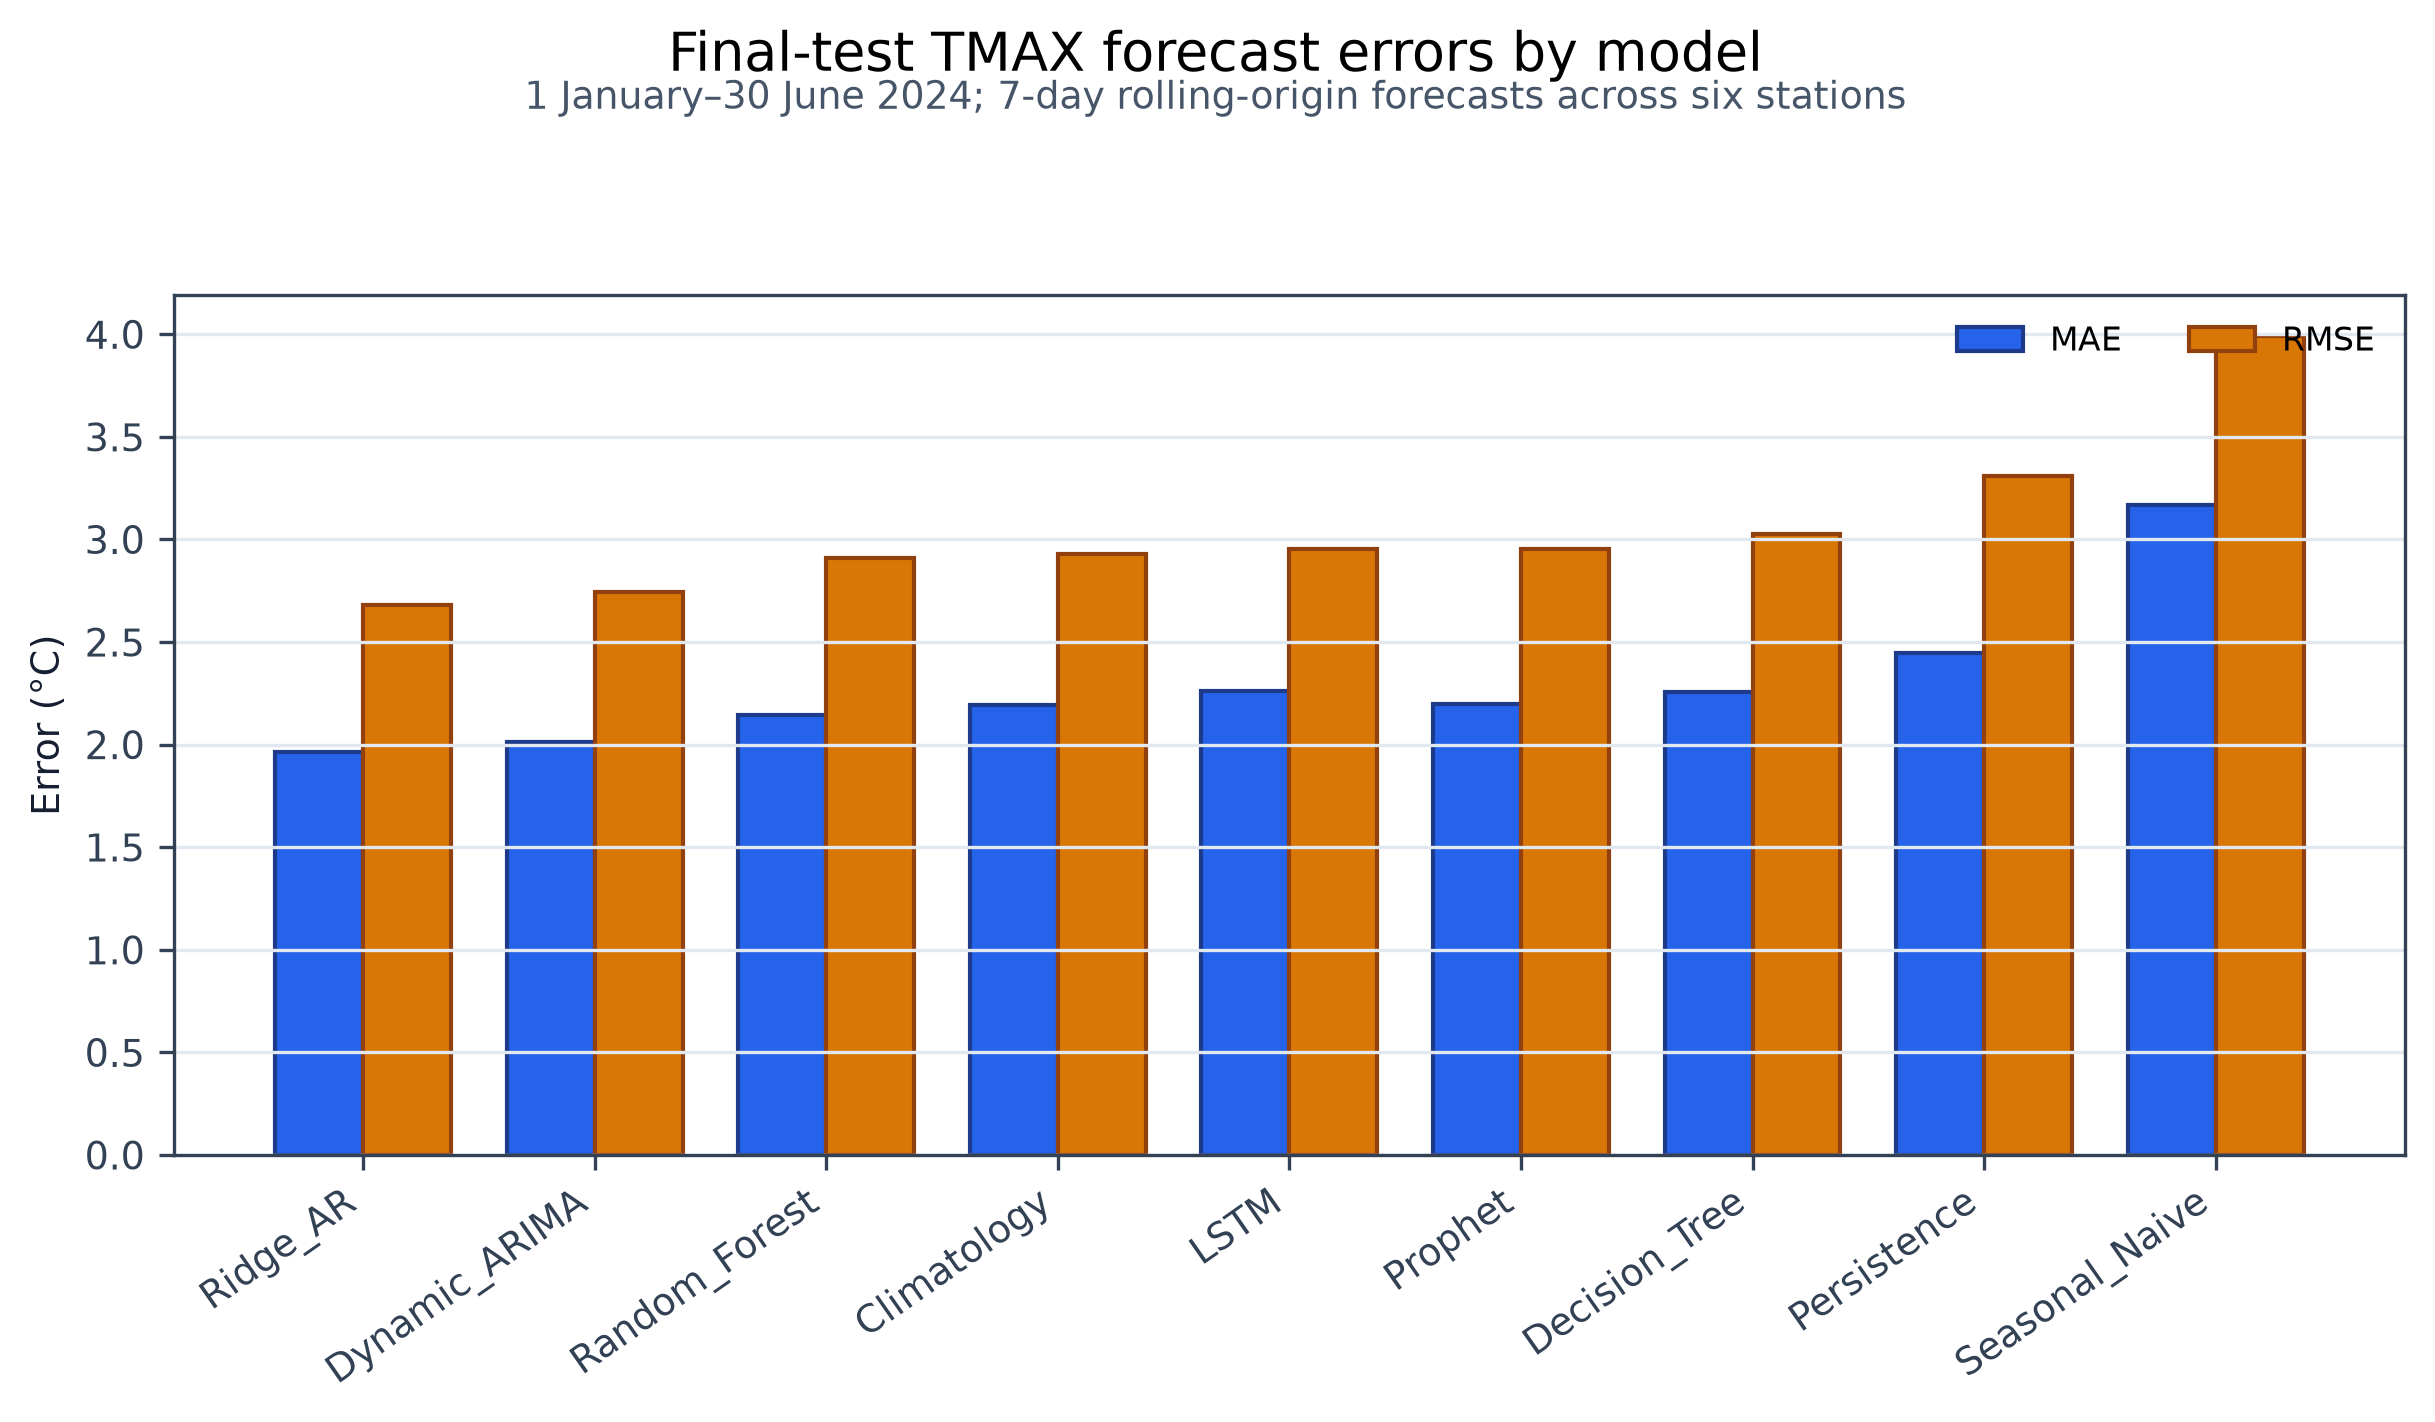

In [4]:
final_view = regression[regression["role"] == "final_test"].sort_values("rmse")[
    ["model", "mae", "rmse", "mape_pct", "smape_pct", "r2", "bias"]
].rename(columns={
    "model": "Model", "mae": "MAE (°C)", "rmse": "RMSE (°C)",
    "mape_pct": "MAPE (%)", "smape_pct": "sMAPE (%)", "r2": "R²", "bias": "Bias (°C)"
})
display(final_view.round(3))
display(Image(filename=str(FIGURES / "final_test_model_errors.png"), width=900))

`Ridge_AR` leads the holdout numerically, but that result does not override the prespecified selection rule. The paired comparison below defines the difference as comparator MAE minus selected-model MAE; positive values favor `Dynamic_ARIMA`.

In [5]:
paired_view = paired[[
    "comparator_model", "mean_mae_difference_comparator_minus_selected",
    "ci95_lower", "ci95_upper", "difference_supported_at_95pct"
]].rename(columns={
    "comparator_model": "Comparator", "mean_mae_difference_comparator_minus_selected": "Δ MAE (°C)",
    "ci95_lower": "95% CI lower", "ci95_upper": "95% CI upper",
    "difference_supported_at_95pct": "95% supported"
})
display(paired_view.round(3))

,Comparator,Δ MAE (°C),95% CI lower,95% CI upper,95% supported
0,Ridge_AR,-0.048,-0.123,0.023,False
1,Dynamic_ARIMA,0.000,0.000,0.000,False
2,Random_Forest,0.134,0.039,0.226,True
3,Climatology,0.180,0.039,0.327,True
4,Prophet,0.186,0.067,0.307,True
5,Decision_Tree,0.246,0.106,0.386,True
6,LSTM,0.248,0.123,0.374,True
7,Persistence,0.434,0.230,0.651,True
8,Seasonal_Naive,1.155,0.967,1.346,True


### Predictive uncertainty and station traces

,Model,MAE CI lower,MAE CI upper,RMSE CI lower,RMSE CI upper,90% half-width (°C),Final coverage
7,Ridge_AR,1.801,2.155,2.438,2.928,3.653,0.860
2,Dynamic_ARIMA,1.837,2.215,2.496,3.002,3.687,0.853
6,Random_Forest,1.951,2.364,2.634,3.189,3.846,0.844
0,Climatology,1.998,2.395,2.688,3.165,3.987,0.831
3,LSTM,2.077,2.459,2.705,3.207,3.839,0.831
5,Prophet,2.009,2.402,2.708,3.205,4.000,0.842
1,Decision_Tree,2.058,2.477,2.738,3.305,3.835,0.824
4,Persistence,2.202,2.709,2.989,3.612,4.400,0.833
8,Seasonal_Naive,2.957,3.392,3.746,4.234,5.200,0.821


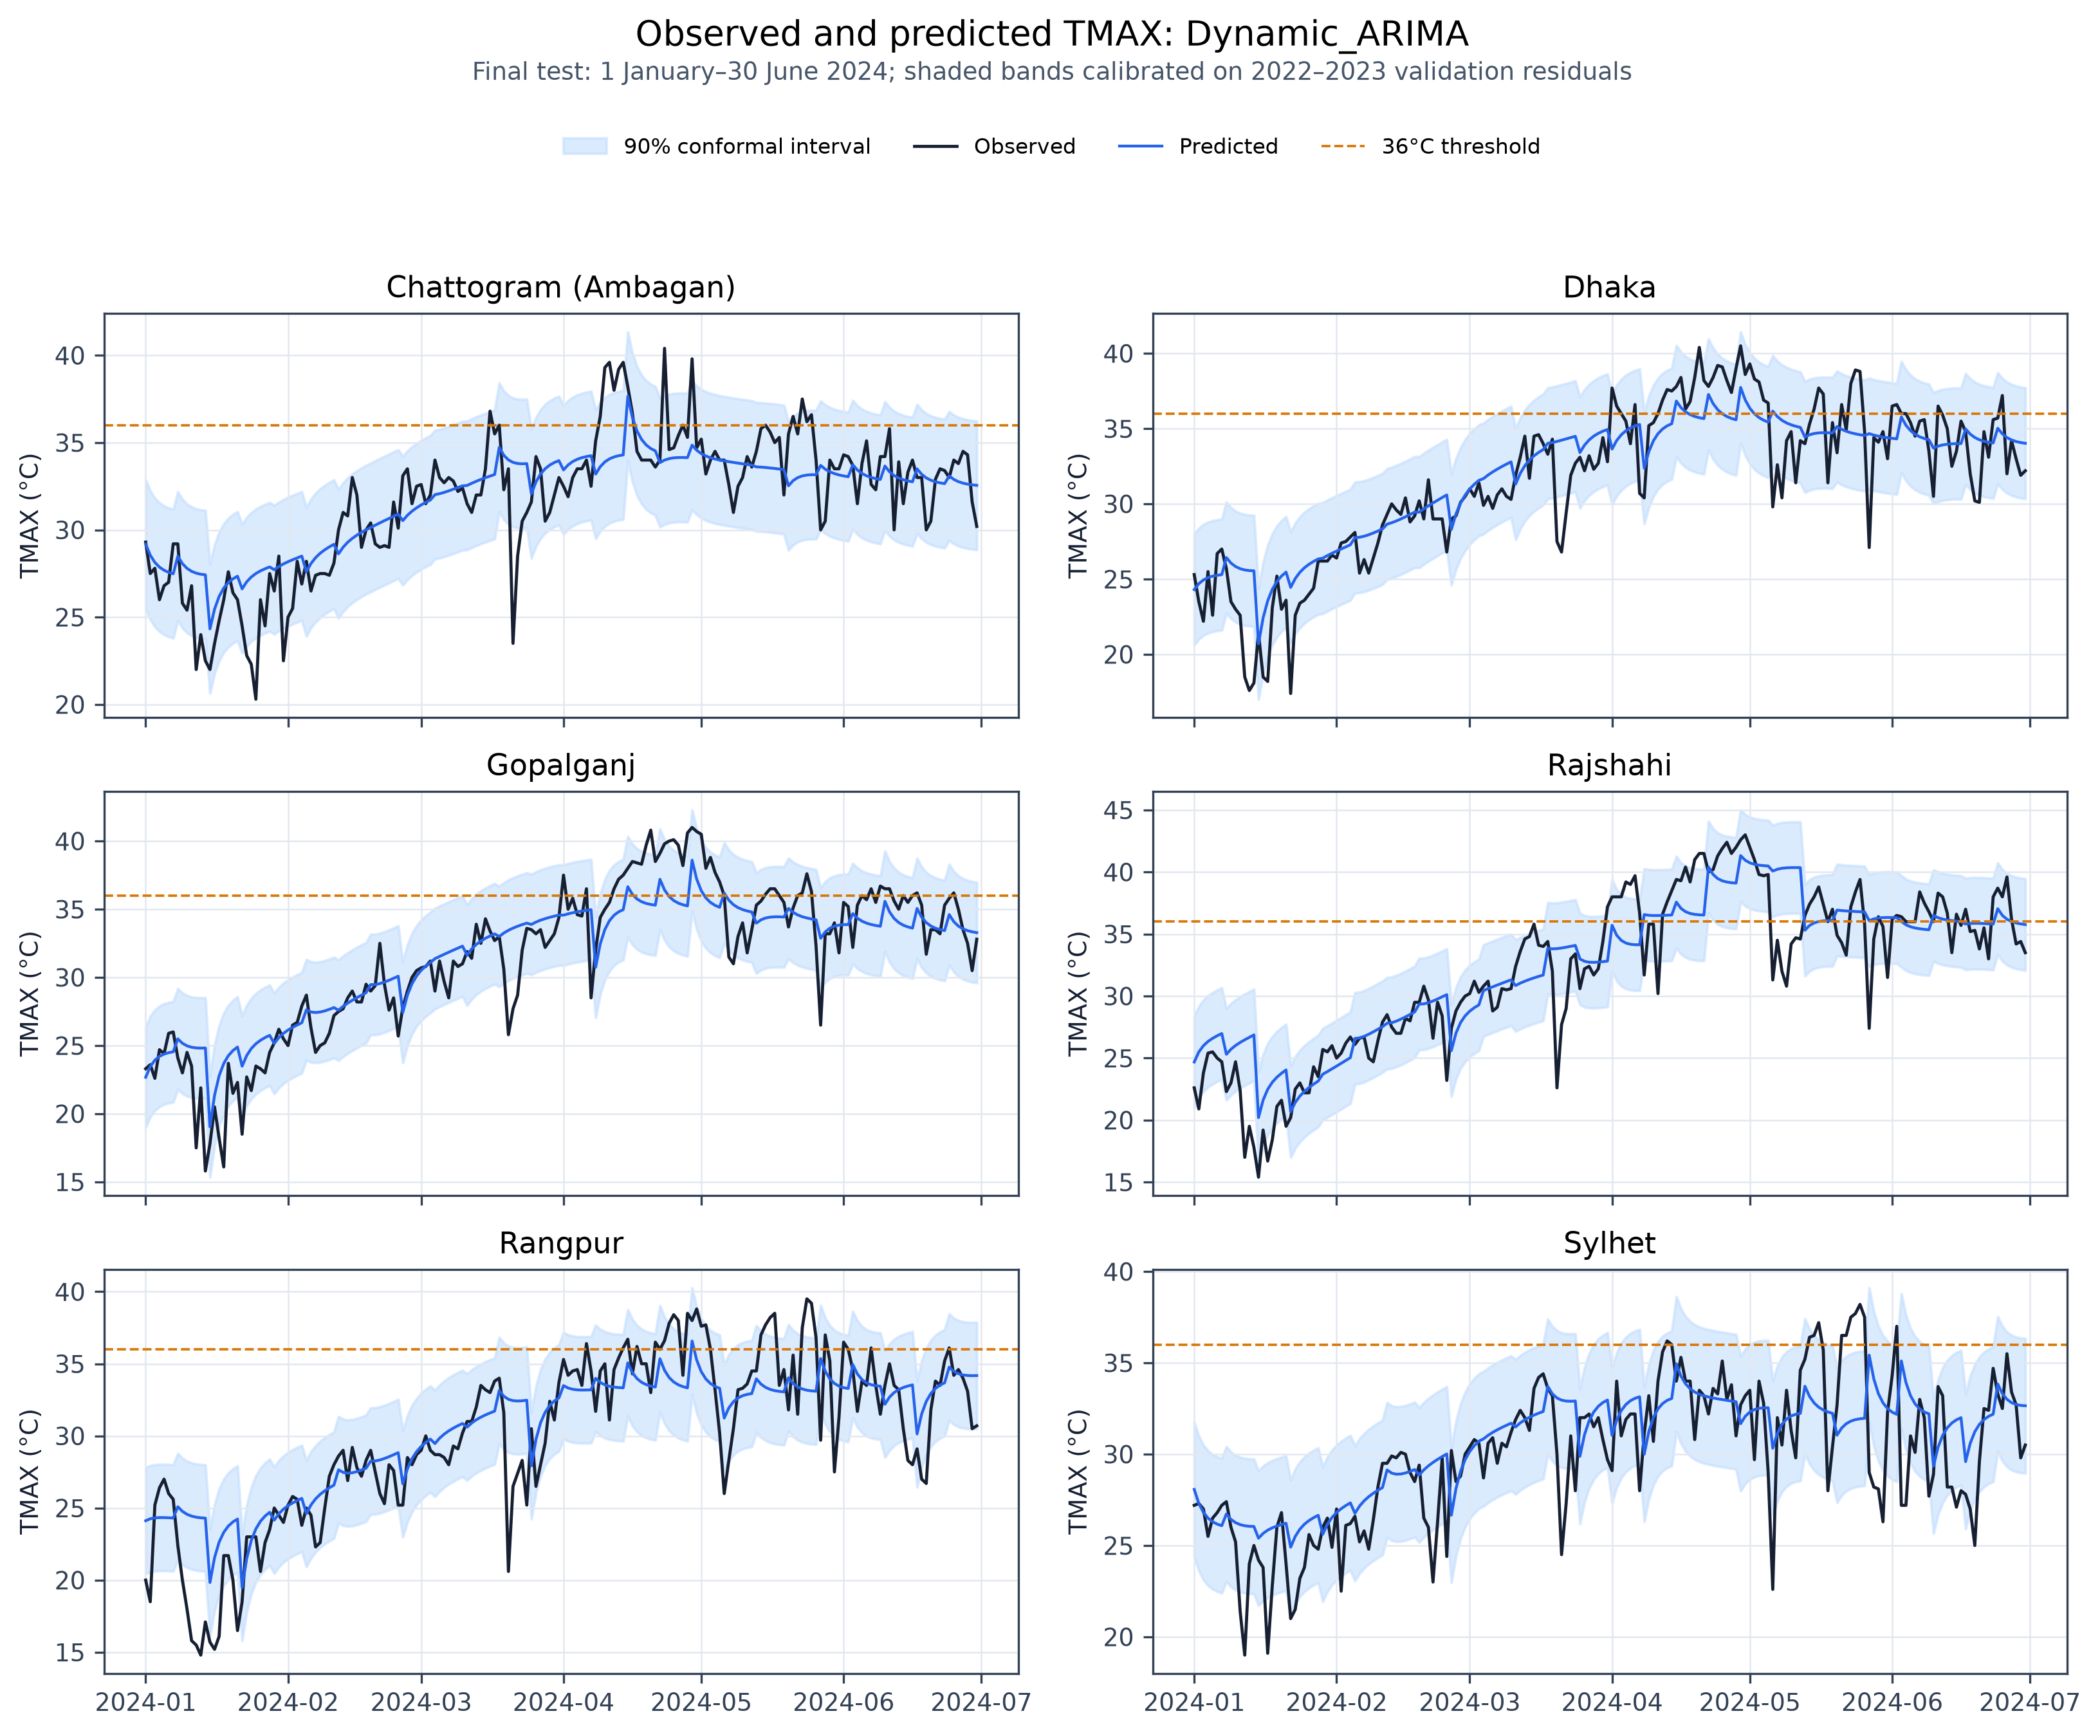

In [6]:
uncertainty_view = uncertainty.sort_values("rmse")[[
    "model", "mae_ci95_lower", "mae_ci95_upper", "rmse_ci95_lower", "rmse_ci95_upper",
    "conformal_half_width_c", "final_test_coverage"
]].rename(columns={
    "model": "Model", "mae_ci95_lower": "MAE CI lower", "mae_ci95_upper": "MAE CI upper",
    "rmse_ci95_lower": "RMSE CI lower", "rmse_ci95_upper": "RMSE CI upper",
    "conformal_half_width_c": "90% half-width (°C)", "final_test_coverage": "Final coverage"
})
display(uncertainty_view.round(3))
display(Image(filename=str(FIGURES / "selected_model_observed_vs_predicted.png"), width=1000))

### Heatwave-day and event performance

,Model,Day precision,Day recall,Day F1,Observed events,Predicted events,Matched events,Event precision,Event recall,Event F1
4,Persistence,0.535,0.649,0.587,23,12,9,0.750,0.391,0.514
1,Decision_Tree,0.497,0.532,0.514,23,12,7,0.583,0.304,0.400
2,Dynamic_ARIMA,0.662,0.331,0.442,23,8,6,0.750,0.261,0.387
8,Seasonal_Naive,0.318,0.325,0.322,23,19,7,0.368,0.304,0.333
7,Ridge_AR,0.667,0.351,0.460,23,9,5,0.556,0.217,0.312
6,Random_Forest,0.780,0.208,0.328,23,7,4,0.571,0.174,0.267
3,LSTM,0.694,0.279,0.398,23,7,4,0.571,0.174,0.267
0,Climatology,0.727,0.104,0.182,23,2,2,1.000,0.087,0.160
5,Prophet,0.608,0.292,0.395,23,2,2,1.000,0.087,0.160


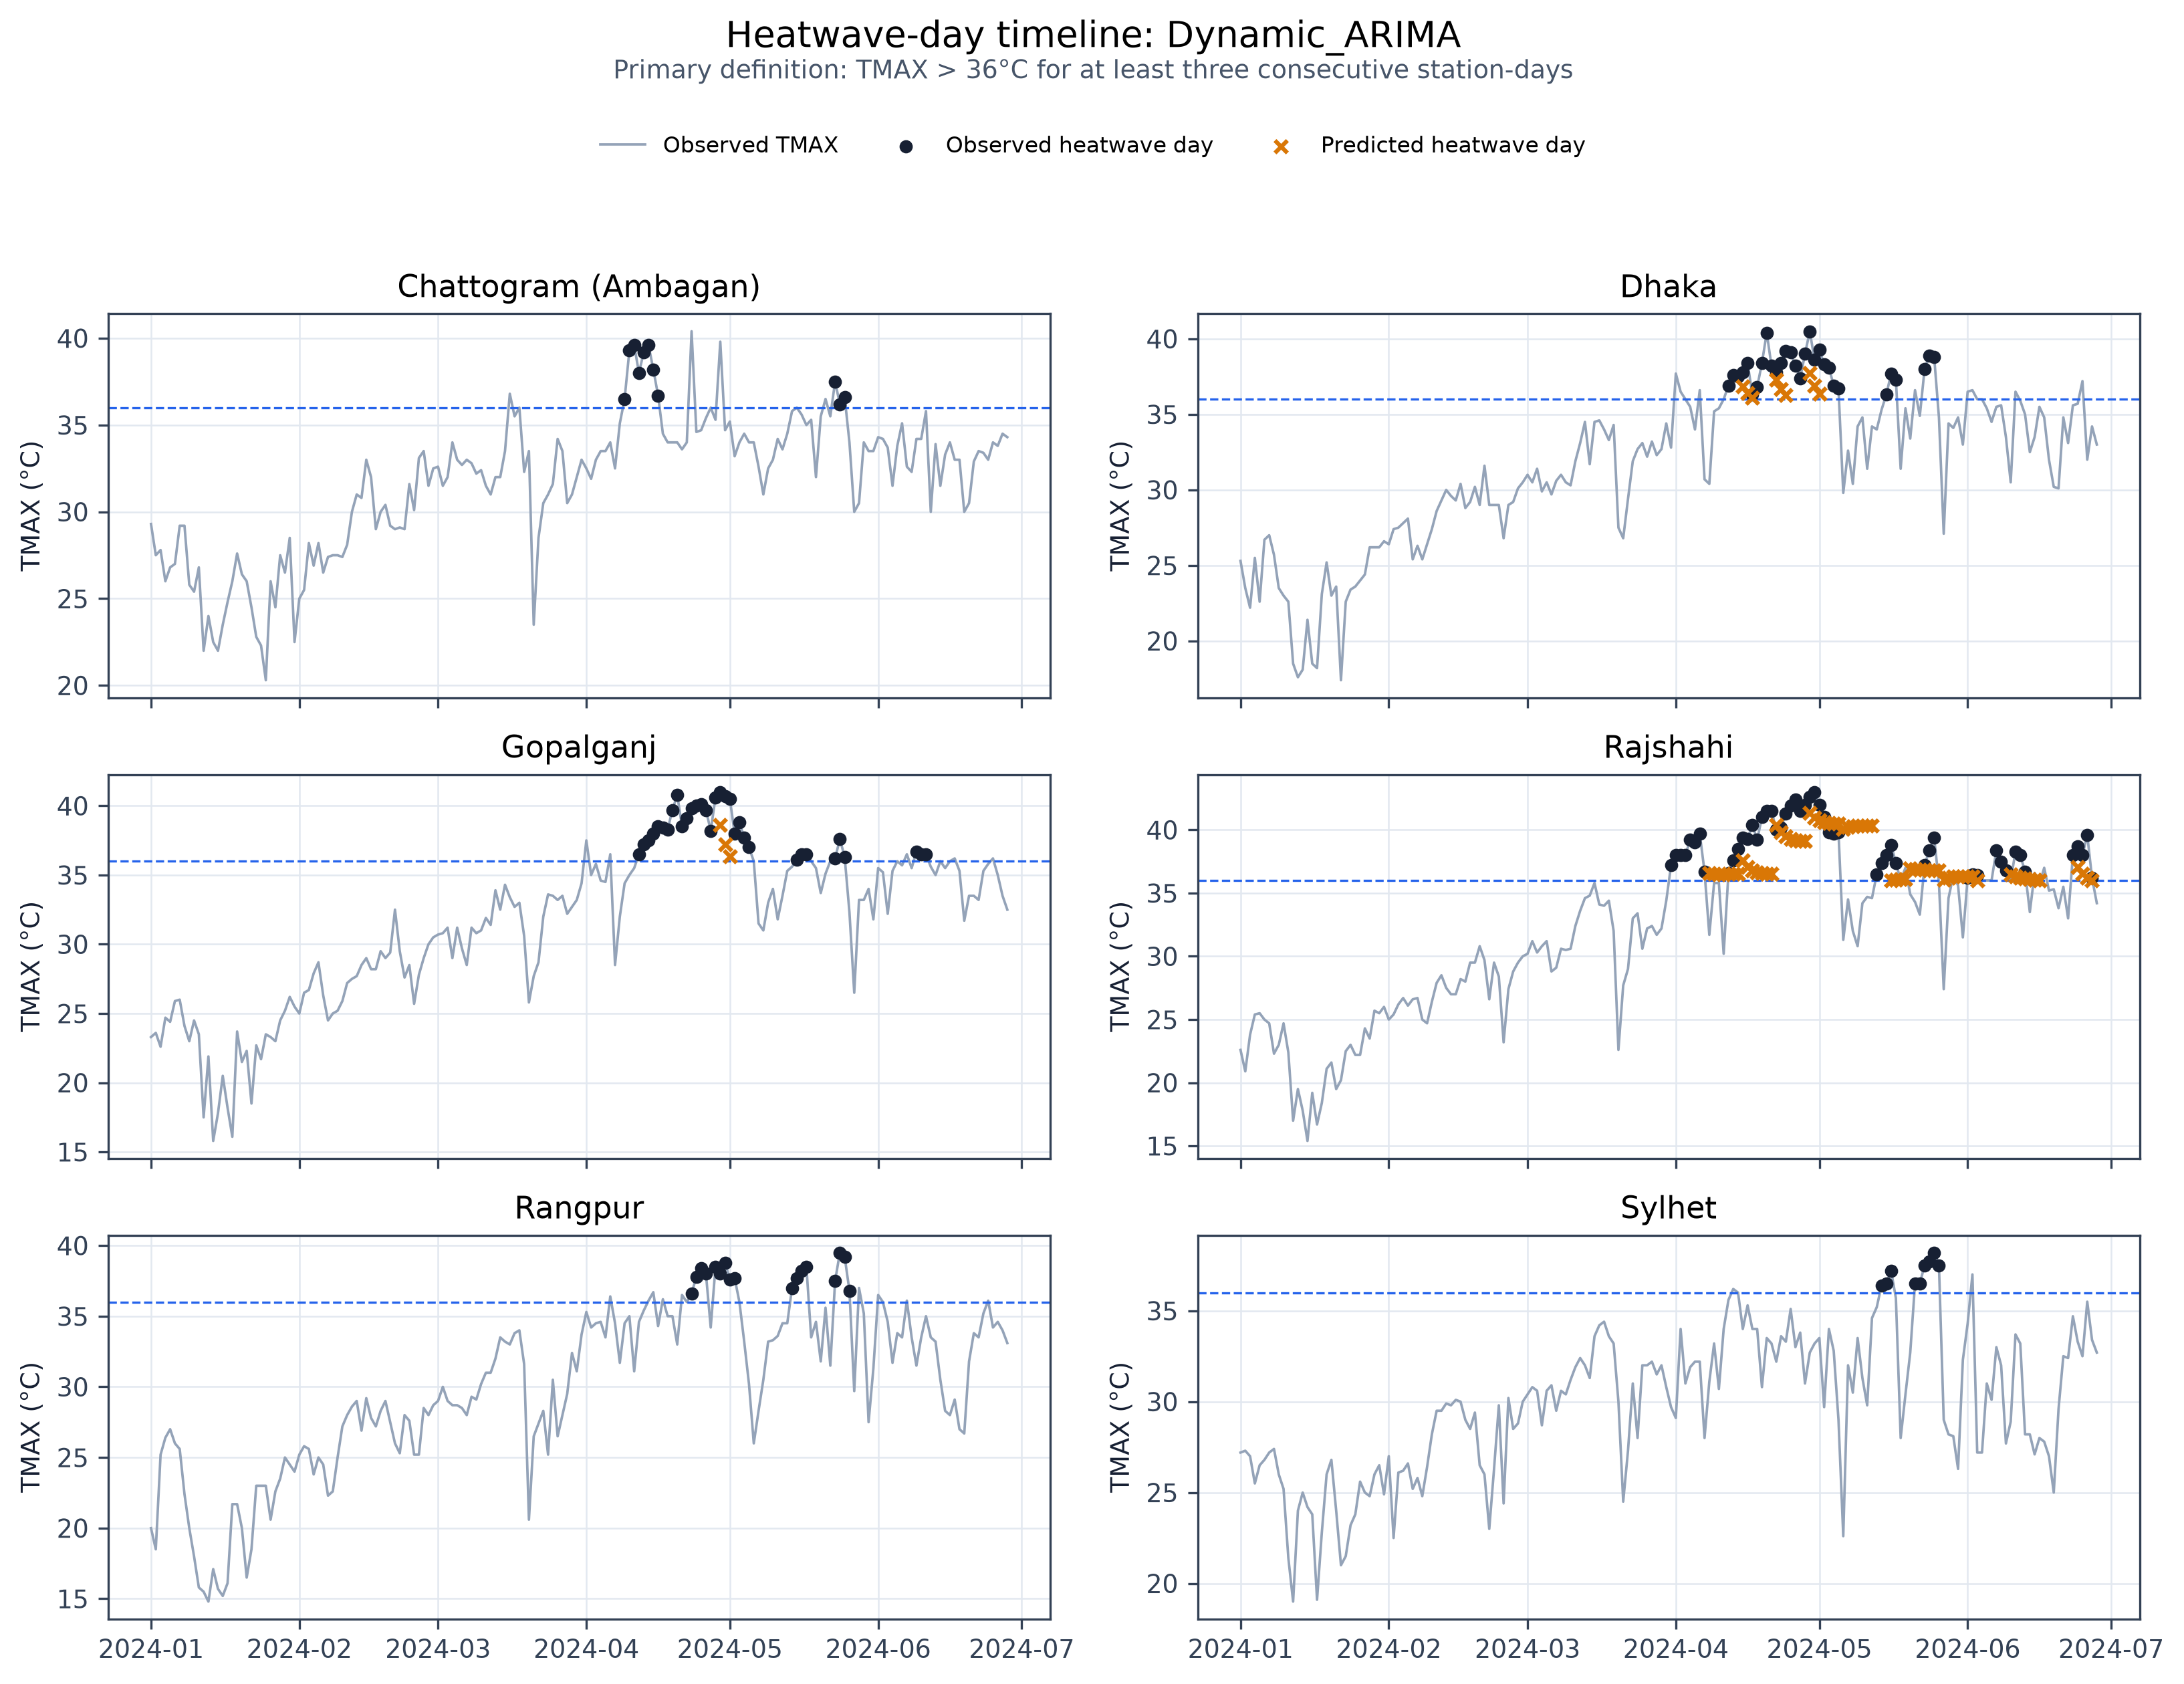

In [7]:
primary_hw = heatwave[(heatwave["role"] == "final_test") & (heatwave["definition"] == "strict_gt_36")]
primary_view = primary_hw.sort_values("event_f1", ascending=False)[[
    "model", "precision", "recall", "f1", "observed_events", "predicted_events",
    "matched_events", "event_precision", "event_recall", "event_f1"
]].rename(columns={
    "model": "Model", "precision": "Day precision", "recall": "Day recall", "f1": "Day F1",
    "observed_events": "Observed events", "predicted_events": "Predicted events",
    "matched_events": "Matched events", "event_precision": "Event precision",
    "event_recall": "Event recall", "event_f1": "Event F1"
})
display(primary_view.round(3))
display(Image(filename=str(FIGURES / "selected_model_heatwave_timeline.png"), width=1000))

## Validation checks

In [8]:
with (AUDIT / "output_validation.json").open() as handle:
    validation_checks = json.load(handle)
display(pd.DataFrame(validation_checks.items(), columns=["Check", "Result"]))
assert validation_checks["all_critical_checks_pass"]

,Check,Result
0,prediction_rows,49248
1,expected_prediction_rows,49248
2,model_set_matches,True
3,duplicate_forecast_keys,0
4,missing_observations,0
5,missing_predictions,0
6,inconsistent_observations_across_models,0
7,forecast_horizons,"[1, 2, 3, 4, 5, 6, 7]"
8,fold_date_ranges,"{'test_2024H1': {'start': '2024-01-01', 'end':..."
9,maximum_mae_recalculation_difference,0.0


## Takeaways

1. The rebuilt evidence supports dynamic harmonic ARIMA as the validation-selected model and Ridge autoregression as the numerically strongest 2024H1 holdout model; their difference is not decisive.
2. Prophet is not the leading model in this experiment, and the original notebook scores should not be reused.
3. Heatwave event detection is a separate, harder task. Persistence has the strongest event F1, while the smooth statistical models often miss threshold crossings.
4. The 90% conformal band undercovers in 2024H1, so uncertainty claims need a distribution-shift caveat.
5. The data support the evaluated 1–7-day station forecast, not a 2037 climate projection or an official nationwide BMD heatwave declaration.